# Point geometries of the pipeline outputs (small area)

Shows the **real point geometries** (WKB `geometry` column of the final parquet files) of

| Pipeline | Geometry in the parquet | Velocity used for the colour |
|---|---|---|
| **COMPASS-Dolphin** | geocoded grid (5 m x 10 m posting), stored in UTM 33N | `mean_velocity` |
| **ISCE2-Dolphin-MintPy** | one point per radar pixel at its ISCE2 lat/lon, stored in WGS84 (CRS84) | `velocity_mintpy` |

for one stack (`STACK`) and a small area in the city centre, to see how the geocoding of the final output works and how the
pipelines differ point by point. Nothing is gridded here.

**Workflow**
1. Geometry CRS of each file (parquet metadata only), and the coverage of the whole dataset
   (all points with coherence > `OVERVIEW_MIN_COHERENCE`, coloured by velocity).
2. Load the points of the area: the row groups are filtered by `lon`/`lat` (parquet statistics), then the WKB
   geometries are decoded and transformed to one metric CRS.
3. Point pattern: spacing between neighbouring points.
4. Static maps: velocity per point for both pipelines, and both point sets on top of each other (zoom).
5. Point-by-point differences: nearest ISCE2 point for every COMPASS point.
6. Interactive map (folium) with satellite / OSM background.

**Conventions**: LOS velocity in mm/yr, negative = away from the satellite. Differences are `ISCE2 − COMPASS`.
The two pipelines use different reference points (see notebook 04), so the velocities can differ by a
constant offset; set `SUBTRACT_AREA_MEDIAN = True` to remove it within the area.
Short stacks (a few months) give noisy velocities.

**Only one pipeline available?** Pipelines without a file for `STACK` are skipped automatically. All sections work with one pipeline, except section 5 (point-by-point differences), which needs both.

In [1]:
import sys
from pathlib import Path

import branca.colormap as bcm
import folium
import geopandas as gpd
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import shapely
from IPython.display import display
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from pyproj import Transformer
from scipy.spatial import cKDTree

try:
    import aducat_val
except ImportError:  # package not installed with `pip install -e .`: use src/ of this repo (see README.md)
    repo_root = next(p for p in Path.cwd().resolve().parents if (p / "src" / "aducat_val").is_dir())
    sys.path.insert(0, str(repo_root / "src"))

from aducat_val import metrics, readers, spatial
from aducat_val.config import METRIC_CRS, VELOCITY_CMAP
from aducat_val.readers import parquet_crs

## Configuration

In [2]:
# ---- Paths: set them to where the data is on your machine ----
DATA_DIR = Path("/home/lukas/projects/ADUCAT/data")
AOI_FILE = DATA_DIR / "AOI/Projektgebiet_ADUCAT-AOI.gpkg"

STACK = "S1_ASC_073_IW1-IW2_VV_20190105_20190228_vienna"

# Area: square around a centre point (lon, lat). Default: Stephansplatz.
CENTER = (16.3725, 48.2085)
HALF_SIZE_M = 300                 # 300 -> 600 m x 600 m (~4k COMPASS and ~6.5k ISCE2 points)

# velocity : column used for the colour; extra : additional columns shown in the interactive popups
PIPELINES = {
    "COMPASS-Dolphin": dict(
        file=DATA_DIR / f"final_outputs/COMPASS-DOLPHIN/{STACK}.parquet",
        velocity="mean_velocity",
        coherence="temporal_coherence",
        extra=["velocity_dolphin", "is_ps", "height"],
        color=readers.COLORS["COMPASS-Dolphin"],
        marker="s",
    ),
    "ISCE2-Dolphin-MintPy": dict(
        file=DATA_DIR / f"final_outputs/isce2-dolphin-mintpy/{STACK}.parquet",
        velocity="velocity_mintpy",
        coherence="temporal_coherence",
        extra=["velocity_mintpy_std", "is_ps", "height"],
        color=readers.COLORS["ISCE2-Dolphin-MintPy"],
        marker="o",
    ),
}

# Keep only the pipelines that have a file for this stack
missing = [name for name, cfg in PIPELINES.items() if not cfg["file"].exists()]
PIPELINES = {name: cfg for name, cfg in PIPELINES.items() if name not in missing}
if not PIPELINES:
    raise FileNotFoundError(f"No pipeline has a file for {STACK}")
for name in missing:
    print(f"Skipped {name}: no file for {STACK}")
print("Pipelines used:", ", ".join(PIPELINES))
HAS_PAIR = len(PIPELINES) == 2               # section 5 (point-by-point differences) needs both
FIRST, SECOND = (list(PIPELINES) + [None])[:2]
SHORT = {"COMPASS-Dolphin": "COMPASS", "ISCE2-Dolphin-MintPy": "ISCE2"}

MIN_COHERENCE = {"COMPASS-Dolphin": 0.0, "ISCE2-Dolphin-MintPy": 0.0}   # 0 = all points (ISCE2 file has only ≥ 0.7)
SUBTRACT_AREA_MEDIAN = False      # True: subtract each pipeline's median velocity in the area

# Overview of the whole dataset (section 1.1); METRIC_CRS from aducat_val.config
OVERVIEW_MIN_COHERENCE = 0.95      # only points with a higher coherence are drawn
OVERVIEW_VEL_LIMIT = None         # colour range ±limit mm/yr; None = 98th percentile of |velocity| (short stacks are noisy)
OVERVIEW_MAX_POINTS = None        # None = all points (~25 s per pipeline); e.g. 2_000_000 for a faster random sample

ZOOM_HALF_SIZE_M = 50             # zoomed overlay of both point sets (section 4)
MAX_PAIR_DIST_M = 7.5             # nearest-neighbour pairs farther apart are not compared (section 5)

VEL_LIMIT = 20                    # colour range -VEL_LIMIT ... +VEL_LIMIT mm/yr
DIFF_LIMIT = 15
CMAP = VELOCITY_CMAP              # red = negative (away from satellite), as in the other notebooks
POINT_SIZE = 6

Skipped COMPASS-Dolphin: no file for S1_ASC_073_IW1-IW2_VV_20190105_20190228_vienna
Pipelines used: ISCE2-Dolphin-MintPy


## Helper functions

In [3]:
def area_bounds_lonlat(center, half_size_m):
    """(lon_min, lat_min, lon_max, lat_max) of a square around `center`, slightly enlarged for the pre-filter."""
    to_m = Transformer.from_crs("EPSG:4326", METRIC_CRS, always_xy=True)
    to_ll = Transformer.from_crs(METRIC_CRS, "EPSG:4326", always_xy=True)
    x, y = to_m.transform(*center)
    pad = half_size_m * 1.1
    lon, lat = to_ll.transform([x - pad, x + pad, x - pad, x + pad], [y - pad, y - pad, y + pad, y + pad])
    return min(lon), min(lat), max(lon), max(lat), (x, y)


def style_axes(ax, extent):
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.set_aspect("equal")
    ax.ticklabel_format(useOffset=False, style="plain")
    ax.tick_params(labelsize=8)
    ax.grid(alpha=0.25)

## 1. Geometry CRS of each file

Read from the GeoParquet metadata only. The `lon`/`lat` columns are always WGS84.

In [4]:
overview = {}
for name, cfg in PIPELINES.items():
    pf = pq.ParquetFile(cfg["file"])
    crs = parquet_crs(pf)
    overview[name] = {
        "points in file": f"{pf.metadata.num_rows:,}",
        "row groups": pf.metadata.num_row_groups,
        "geometry CRS": f"{crs.name} ({crs.to_epsg() or crs.to_string()[:30]})",
        "velocity column": cfg["velocity"],
    }
display(pd.DataFrame(overview))

,ISCE2-Dolphin-MintPy
points in file,"15,337,853"
row groups,16
geometry CRS,WGS 84 (CRS84) (OGC:CRS84)
velocity column,velocity_mintpy


### 1.1 Coverage of the whole dataset

All points of each file with coherence > `OVERVIEW_MIN_COHERENCE`, coloured by their velocity. Only the `lon`/`lat`,
velocity and coherence columns are read (the `lon`/`lat` columns are identical to the decoded geometry, see section 2),
and the coherence filter is applied while reading. Black outline: project AOI; small square: the area of the
following sections. With millions of points the map looks like a raster, but every coloured dot is a point;
white means no point (water, vegetation / low coherence, outside the processed area).

ERROR 1: PROJ: proj_create_from_database: Open of /home/lukas/miniforge3/envs/geo_env/share/proj failed


,ISCE2-Dolphin-MintPy
points in file,"15,337,853"
coherence > 0.95,"14,076,807"
share [%],91.8
points drawn,"14,076,807"


velocity: median -1.3 mm/yr, |v| P50 / P98 = 14.7 / 71.2 mm/yr -> colour range ±71 mm/yr


/tmp/claude-1000/ipykernel_50/1510802603.py:33: UserWarning: The pixel maker ',' is not supported on scatter(); using a finite-sized square instead, which is not necessarily 1 pixel in size. Use the square marker 's' instead to suppress this warning.
  ax.scatter(x, y, c=v, cmap=CMAP, norm=norm, s=1, marker=",", linewidths=0, rasterized=True)   # "," = one pixel per point, full colour


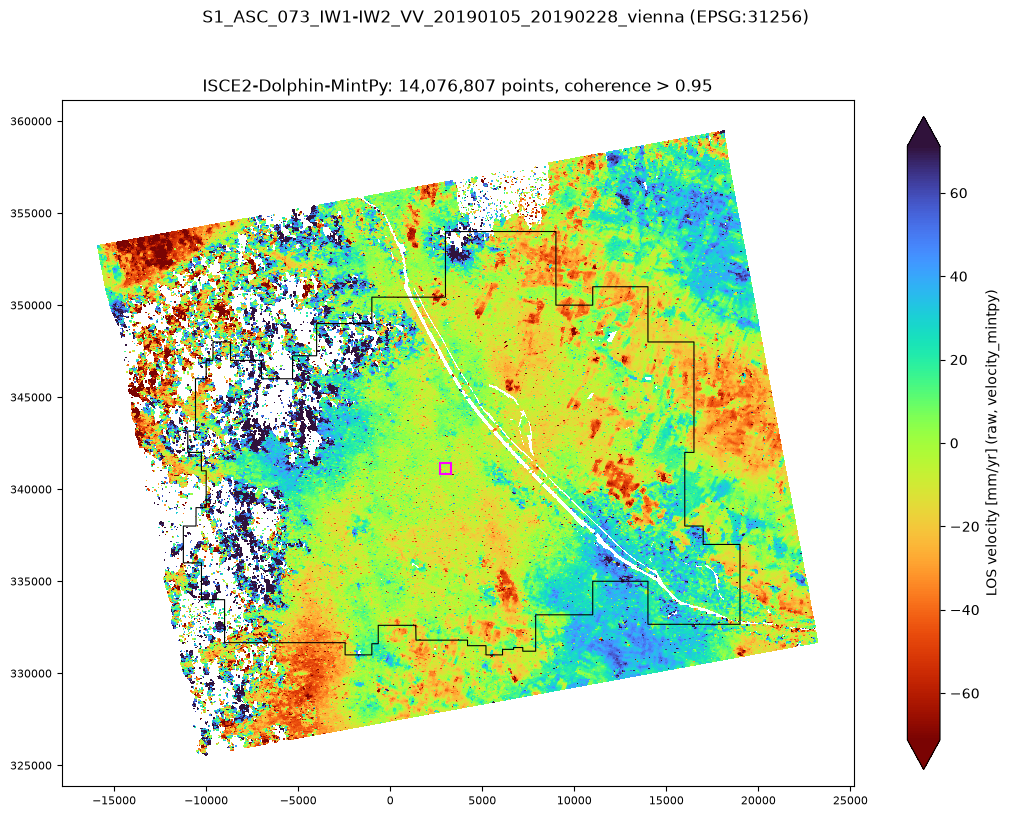

In [5]:
aoi_metric = gpd.read_file(AOI_FILE).to_crs(METRIC_CRS)
to_metric = Transformer.from_crs("EPSG:4326", METRIC_CRS, always_xy=True)
cx, cy = to_metric.transform(*CENTER)
rng = np.random.default_rng(0)

overview_points, coverage = {}, {}
for name, cfg in PIPELINES.items():
    table = pq.read_table(cfg["file"], columns=["lon", "lat", cfg["velocity"], cfg["coherence"]],
                          filters=[(cfg["coherence"], ">", OVERVIEW_MIN_COHERENCE)])
    n_total = pq.ParquetFile(cfg["file"]).metadata.num_rows
    keep = np.arange(table.num_rows)
    if OVERVIEW_MAX_POINTS and table.num_rows > OVERVIEW_MAX_POINTS:
        keep = np.sort(rng.choice(table.num_rows, OVERVIEW_MAX_POINTS, replace=False))
    x, y = to_metric.transform(table["lon"].to_numpy()[keep], table["lat"].to_numpy()[keep])
    overview_points[name] = (x, y, table[cfg["velocity"]].to_numpy()[keep])
    coverage[name] = {
        "points in file": n_total,
        f"coherence > {OVERVIEW_MIN_COHERENCE}": table.num_rows,
        "share [%]": 100 * table.num_rows / n_total,
        "points drawn": len(keep),
    }
display(pd.DataFrame(coverage).style.format("{:,.0f}").format("{:.1f}", subset=pd.IndexSlice[["share [%]"], :]))

n = len(overview_points)
fig, axes = plt.subplots(1, n, figsize=(10 * n, 8.5), sharex=True, sharey=True, constrained_layout=True,
                         squeeze=False)
all_v = np.concatenate([v for _, _, v in overview_points.values()])
vlim = OVERVIEW_VEL_LIMIT or float(np.nanpercentile(np.abs(all_v), 98))
print(f"velocity: median {np.nanmedian(all_v):.1f} mm/yr, |v| P50 / P98 = {np.nanpercentile(np.abs(all_v), 50):.1f} / "
      f"{np.nanpercentile(np.abs(all_v), 98):.1f} mm/yr -> colour range ±{vlim:.0f} mm/yr")
norm = Normalize(-vlim, vlim)
for ax, (name, (x, y, v)) in zip(axes.ravel(), overview_points.items()):
    ax.scatter(x, y, c=v, cmap=CMAP, norm=norm, s=1, marker=",", linewidths=0, rasterized=True)   # "," = one pixel per point, full colour
    aoi_metric.boundary.plot(ax=ax, color="black", lw=0.8)
    ax.add_patch(plt.Rectangle((cx - HALF_SIZE_M, cy - HALF_SIZE_M), 2 * HALF_SIZE_M, 2 * HALF_SIZE_M,
                               fill=False, color="magenta", lw=1.5))
    ax.set_title(f"{name}: {len(x):,} points, coherence > {OVERVIEW_MIN_COHERENCE}")
    ax.set_aspect("equal")
    ax.ticklabel_format(useOffset=False, style="plain")
    ax.tick_params(labelsize=8)
fig.colorbar(ScalarMappable(norm, CMAP), ax=axes.ravel().tolist(), shrink=0.8, extend="both",
             label=f"LOS velocity [mm/yr] (raw, {', '.join(PIPELINES[n]['velocity'] for n in overview_points)})")
fig.suptitle(f"{STACK} ({METRIC_CRS})")
plt.show()
del overview_points      # free the memory (millions of points)

## 2. Load the points of the area

`pq.read_table(filters=...)` skips row groups whose `lon`/`lat` statistics do not overlap the area, so only a
small part of the 1.5 GB files is read. Each geometry is decoded in its own CRS and transformed to `METRIC_CRS`.
The check at the end compares the decoded geometry with the `lon`/`lat` columns (should be ~0 m).

In [6]:
lon0, lat0, lon1, lat1, (CX, CY) = area_bounds_lonlat(CENTER, HALF_SIZE_M)
EXTENT = (CX - HALF_SIZE_M, CX + HALF_SIZE_M, CY - HALF_SIZE_M, CY + HALF_SIZE_M)
to_metric_from_ll = Transformer.from_crs("EPSG:4326", METRIC_CRS, always_xy=True)

points, check = {}, {}
for name, cfg in PIPELINES.items():
    pf = pq.ParquetFile(cfg["file"])
    columns = ["lon", "lat", "geometry", cfg["velocity"], cfg["coherence"]] + cfg["extra"]
    table = pq.read_table(cfg["file"], columns=columns,
                          filters=[("lon", ">=", lon0), ("lon", "<=", lon1), ("lat", ">=", lat0), ("lat", "<=", lat1)])
    df = table.drop(["geometry"]).to_pandas()
    gdf = gpd.GeoDataFrame(df, geometry=shapely.from_wkb(table["geometry"].to_numpy()), crs=parquet_crs(pf))
    gdf = gdf.to_crs(METRIC_CRS)

    x, y = gdf.geometry.x.to_numpy(), gdf.geometry.y.to_numpy()
    keep = (x >= EXTENT[0]) & (x <= EXTENT[1]) & (y >= EXTENT[2]) & (y <= EXTENT[3])
    keep &= gdf[cfg["coherence"]].to_numpy() >= MIN_COHERENCE[name]
    gdf = gdf[keep].reset_index(drop=True)
    gdf = gdf.rename(columns={cfg["velocity"]: "velocity", cfg["coherence"]: "coherence"})

    # geometry vs lon/lat columns
    xl, yl = to_metric_from_ll.transform(gdf["lon"].to_numpy(), gdf["lat"].to_numpy())
    offset = np.hypot(gdf.geometry.x - xl, gdf.geometry.y - yl)

    check[name] = {
        "points in area": len(gdf),
        "median velocity [mm/yr]": gdf["velocity"].median(),
        "median coherence": gdf["coherence"].median(),
        "PS points [%]": 100 * gdf["is_ps"].mean(),
        "max |geometry − lon/lat| [m]": offset.max(),
    }
    points[name] = gdf

AREA_MEDIAN = pd.Series({name: gdf["velocity"].median() for name, gdf in points.items()})
for name, gdf in points.items():
    gdf["velocity_plot"] = gdf["velocity"] - (AREA_MEDIAN[name] if SUBTRACT_AREA_MEDIAN else 0.0)
VEL_INFO = ("area median subtracted" if SUBTRACT_AREA_MEDIAN
            else "raw velocities" + (" (different reference points)" if HAS_PAIR else ""))

display(pd.DataFrame(check).style.format("{:,.2f}").format("{:,.0f}", subset=pd.IndexSlice[["points in area"], :]))

,ISCE2-Dolphin-MintPy
points in area,"6,540"
median velocity [mm/yr],-3.18
median coherence,1.00
PS points [%],34.25
max |geometry − lon/lat| [m],0.00


## 3. Point pattern

Distance to the nearest other point of the same pipeline, and the typical spacing in x (east) and y (north).
COMPASS points sit on a regular geocoded grid. ISCE2 points are radar pixels (~2.3 m slant range ≈ 4 m on ground x
~15.6 m azimuth) placed at their own geocoded position, so their pattern is irregular and follows the radar geometry.

In [7]:
spacing = {}
for name, gdf in points.items():
    xy = np.column_stack([gdf.geometry.x, gdf.geometry.y])
    d, i = cKDTree(xy).query(xy, k=2)
    dxy = np.abs(xy[i[:, 1]] - xy)
    spacing[name] = {
        "nearest neighbour: median [m]": np.median(d[:, 1]),
        "nearest neighbour: P5 [m]": np.percentile(d[:, 1], 5),
        "nearest neighbour: P95 [m]": np.percentile(d[:, 1], 95),
        "points per hectare": len(gdf) / ((2 * HALF_SIZE_M) ** 2 / 1e4),
    }
show_spacing = pd.DataFrame(spacing)
display(show_spacing.style.format("{:,.2f}"))

,ISCE2-Dolphin-MintPy
nearest neighbour: median [m],3.71
nearest neighbour: P5 [m],2.82
nearest neighbour: P95 [m],5.17
points per hectare,181.67


## 4. Static maps

### 4.1 Velocity per point (one panel per pipeline)

Every point is drawn at its decoded geometry, coloured by its velocity. The dashed square marks the zoom of 4.2.

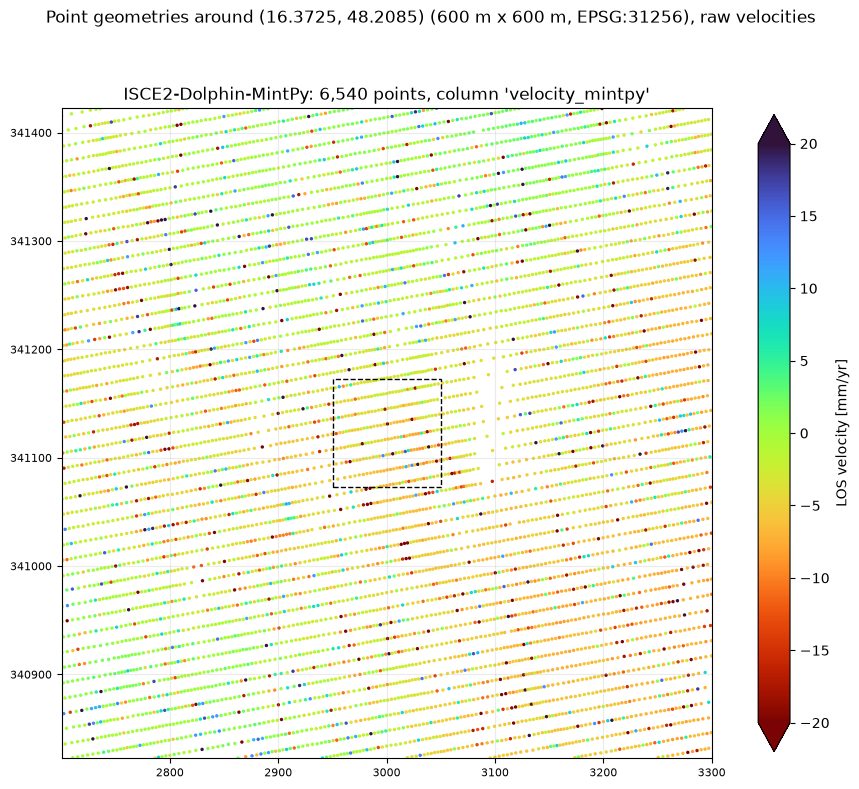

In [8]:
norm = Normalize(-VEL_LIMIT, VEL_LIMIT)
n = len(points)
fig, axes = plt.subplots(1, n, figsize=(8.5 * n, 8.3), sharex=True, sharey=True, constrained_layout=True,
                         squeeze=False)
axes = axes.ravel()
zoom = (CX - ZOOM_HALF_SIZE_M, CX + ZOOM_HALF_SIZE_M, CY - ZOOM_HALF_SIZE_M, CY + ZOOM_HALF_SIZE_M)

for ax, (name, gdf) in zip(axes, points.items()):
    ax.scatter(gdf.geometry.x, gdf.geometry.y, c=gdf["velocity_plot"], cmap=CMAP, norm=norm,
               s=POINT_SIZE, marker=PIPELINES[name]["marker"], linewidths=0)
    ax.add_patch(plt.Rectangle((zoom[0], zoom[2]), zoom[1] - zoom[0], zoom[3] - zoom[2],
                               fill=False, ls="--", lw=1, color="k"))
    ax.set_title(f"{name}: {len(gdf):,} points, column '{PIPELINES[name]['velocity']}'")
    style_axes(ax, EXTENT)

fig.colorbar(ScalarMappable(norm, CMAP), ax=axes, shrink=0.8, extend="both", label="LOS velocity [mm/yr]")
fig.suptitle(f"Point geometries around {CENTER} ({2 * HALF_SIZE_M} m x {2 * HALF_SIZE_M} m, {METRIC_CRS}), {VEL_INFO}")
plt.show()

### 4.2 Point sets on top of each other (zoom)

Left: only the positions (COMPASS squares, ISCE2 circles; only the available pipelines). Right: the same coloured by velocity, which shows
whether neighbouring points of the two pipelines agree.

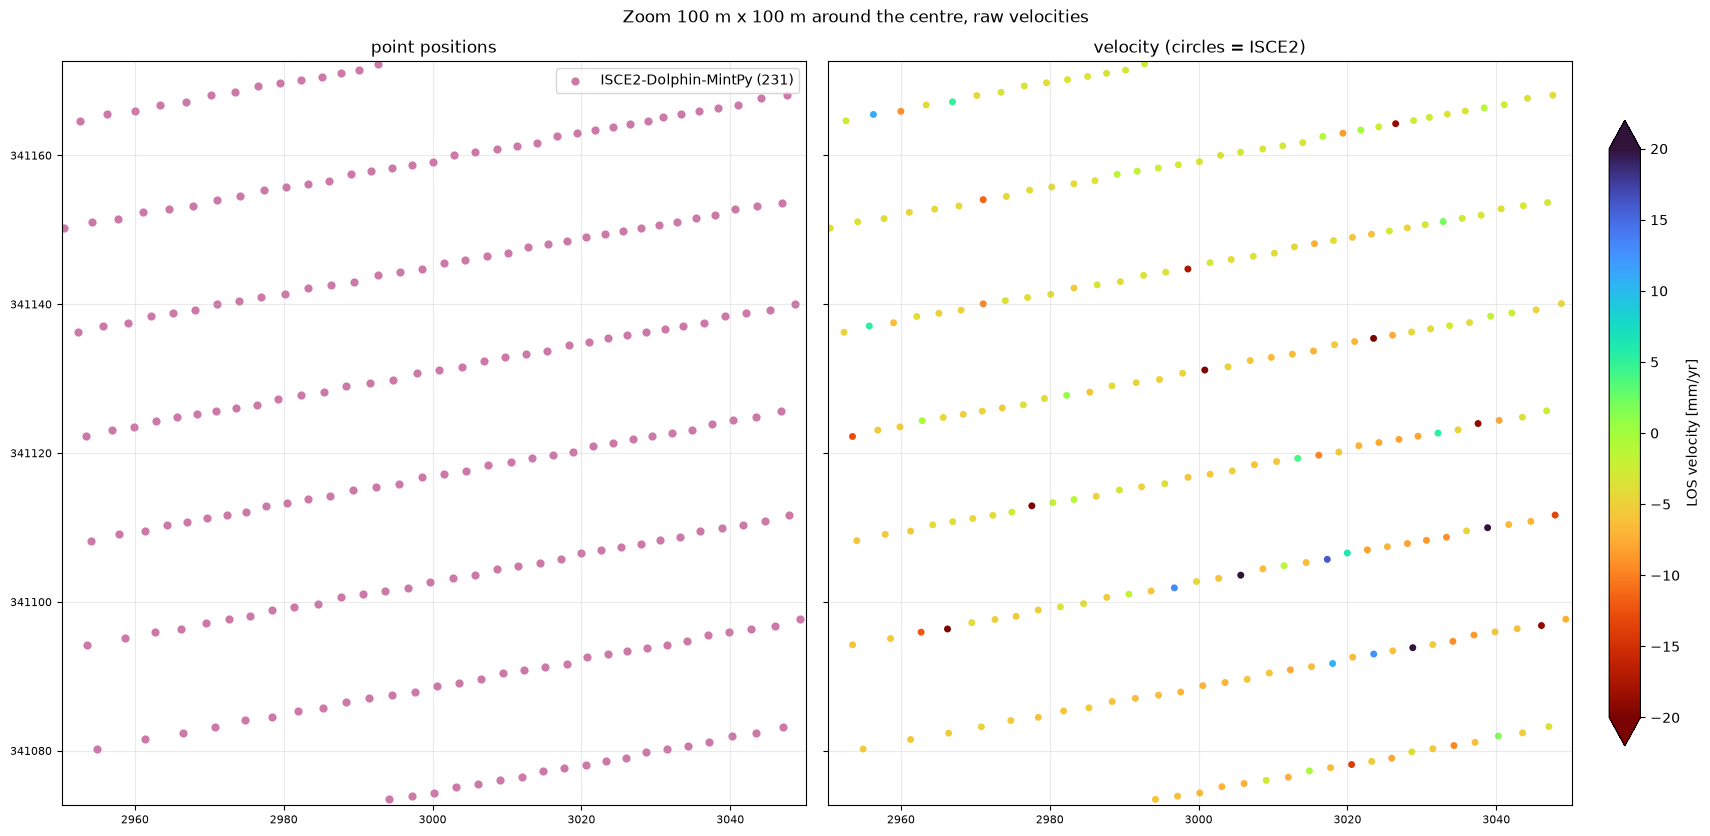

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(17, 8.3), sharex=True, sharey=True, constrained_layout=True)
for name, gdf in points.items():
    cfg = PIPELINES[name]
    inz = gdf.cx[zoom[0]:zoom[1], zoom[2]:zoom[3]]
    axes[0].scatter(inz.geometry.x, inz.geometry.y, s=40 if cfg["marker"] == "s" else 22, marker=cfg["marker"],
                    facecolors="none" if cfg["marker"] == "s" else cfg["color"], edgecolors=cfg["color"],
                    linewidths=1.2, label=f"{name} ({len(inz)})")
    axes[1].scatter(inz.geometry.x, inz.geometry.y, c=inz["velocity_plot"], cmap=CMAP, norm=norm,
                    s=60 if cfg["marker"] == "s" else 25, marker=cfg["marker"],
                    edgecolors="k" if cfg["marker"] == "s" else "none", linewidths=0.4)
axes[0].legend(loc="upper right")
axes[0].set_title("point positions")
axes[1].set_title("velocity (" + ", ".join(f"{'squares' if PIPELINES[n]['marker'] == 's' else 'circles'} = {SHORT[n]}"
                                         for n in points) + ")")
for ax in axes:
    style_axes(ax, zoom)
fig.colorbar(ScalarMappable(norm, CMAP), ax=axes[1], shrink=0.8, extend="both", label="LOS velocity [mm/yr]")
fig.suptitle(f"Zoom {2 * ZOOM_HALF_SIZE_M} m x {2 * ZOOM_HALF_SIZE_M} m around the centre, {VEL_INFO}")
plt.show()

## 5. Point-by-point differences (needs both pipelines)

For every COMPASS point, the nearest ISCE2 point is searched. Pairs farther apart than `MAX_PAIR_DIST_M` are
dropped. The difference `ISCE2 − COMPASS` is plotted at the COMPASS position.
Note: the nearest point is not necessarily the same scatterer (different geometry and resolution), so single
differences are noisy; look at the spatial pattern and the statistics.

In [10]:
if not HAS_PAIR:
    print("Section 5 skipped: only one pipeline available (" + ", ".join(PIPELINES) + ")")
else:
    a, b = points[FIRST], points[SECOND]
    xy_a = np.column_stack([a.geometry.x, a.geometry.y])
    xy_b = np.column_stack([b.geometry.x, b.geometry.y])
    paired, idx, dist = spatial.nearest_pairs(xy_a, xy_b, MAX_PAIR_DIST_M)

    pairs = pd.DataFrame({
        "x": xy_a[paired, 0], "y": xy_a[paired, 1], "distance": dist,
        SHORT[FIRST]: a.loc[paired, "velocity_plot"].to_numpy(),
        SHORT[SECOND]: b["velocity_plot"].to_numpy()[idx],
    })
    pairs["diff"] = pairs[SHORT[SECOND]] - pairs[SHORT[FIRST]]
    m = metrics.difference_metrics(pairs[SHORT[FIRST]], pairs[SHORT[SECOND]])
    pair_stats = pd.Series({
        "COMPASS points with a partner": f"{paired.sum():,} of {len(a):,} ({100 * paired.mean():.0f} %)",
        "median pair distance [m]": f"{pairs['distance'].median():.2f}",
        **{k: f"{v:.3f}" if "r" == k[-1] or "ρ" in k else f"{v:,.2f}" for k, v in m.items() if k != "N"},
    })
    display(pair_stats.to_frame(f"{SHORT[SECOND]} − {SHORT[FIRST]}, {VEL_INFO}"))

Section 5 skipped: only one pipeline available (ISCE2-Dolphin-MintPy)


In [11]:
if not HAS_PAIR:
    print("Section 5 skipped: only one pipeline available (" + ", ".join(PIPELINES) + ")")
else:
    fig, (ax_map, ax_sc) = plt.subplots(1, 2, figsize=(17, 7.5), gridspec_kw={"width_ratios": [1.15, 1]})
    diff_norm = Normalize(-DIFF_LIMIT, DIFF_LIMIT)
    ax_map.scatter(pairs["x"], pairs["y"], c=pairs["diff"], cmap="RdBu", norm=diff_norm, s=POINT_SIZE, marker="s",
                   linewidths=0)
    style_axes(ax_map, EXTENT)
    ax_map.set_title(f"{SHORT[SECOND]} − {SHORT[FIRST]} at the COMPASS points (pairs ≤ {MAX_PAIR_DIST_M} m)")
    fig.colorbar(ScalarMappable(diff_norm, "RdBu"), ax=ax_map, shrink=0.8, extend="both", label="mm/yr")

    lim = VEL_LIMIT * 1.5
    hb = ax_sc.hexbin(pairs[SHORT[FIRST]], pairs[SHORT[SECOND]], gridsize=60, extent=(-lim, lim, -lim, lim),
                      bins="log", mincnt=1, cmap="viridis")
    ax_sc.plot([-lim, lim], [-lim, lim], "k--", lw=1)
    ax_sc.set(xlim=(-lim, lim), ylim=(-lim, lim), aspect="equal",
              xlabel=f"{FIRST} [mm/yr]", ylabel=f"{SECOND} [mm/yr]", title="Velocity of the point pairs")
    ax_sc.grid(alpha=0.3)
    fig.colorbar(hb, ax=ax_sc, shrink=0.8, label="pairs per hexagon")
    fig.suptitle(VEL_INFO)
    plt.tight_layout()
    plt.show()

Section 5 skipped: only one pipeline available (ISCE2-Dolphin-MintPy)


## 6. Interactive map

One layer per pipeline (switch them in the layer control, top right) on OpenStreetMap or Esri satellite imagery.
Click a point for its values. COMPASS points have a black outline, ISCE2 points have none.

In [12]:
colormap = bcm.LinearColormap([mpl.colors.to_hex(mpl.colormaps[CMAP](v)) for v in np.linspace(0, 1, 11)],
                              vmin=-VEL_LIMIT, vmax=VEL_LIMIT, caption=f"LOS velocity [mm/yr], {VEL_INFO}")

m = folium.Map(location=[CENTER[1], CENTER[0]], zoom_start=17, max_zoom=22, tiles=None, control_scale=True)
folium.TileLayer("OpenStreetMap", name="OpenStreetMap", max_zoom=22, max_native_zoom=19).add_to(m)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri World Imagery", name="Esri satellite", max_zoom=22, max_native_zoom=19,
).add_to(m)

for name, gdf in points.items():
    cfg = PIPELINES[name]
    # one GeoJSON layer per pipeline (much smaller than one marker object per point);
    # positions come from the decoded geometry, not from the lon/lat columns
    cols = ["velocity", "coherence"] + cfg["extra"]
    layer_gdf = gdf[cols + ["geometry"]].to_crs("EPSG:4326").round(2)
    layer_gdf["fill"] = [colormap(v) for v in np.clip(gdf["velocity_plot"].to_numpy(), -VEL_LIMIT, VEL_LIMIT)]
    outline = cfg["marker"] == "s"
    folium.GeoJson(
        layer_gdf,
        name=f"{name} ({len(gdf):,} points)",
        marker=folium.CircleMarker(radius=3 if outline else 2.5, fill=True, fill_opacity=0.9),
        style_function=lambda f, outline=outline: {
            "fillColor": f["properties"]["fill"], "color": "black" if outline else f["properties"]["fill"],
            "weight": 0.6 if outline else 0},
        popup=folium.GeoJsonPopup(fields=cols, aliases=[f"{cfg['velocity']} [mm/yr]" if c == "velocity" else c
                                                        for c in cols]),
    ).add_to(m)

colormap.add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
m

## Observations (2025 stack, Stephansplatz, first run)

* **Geometry vs lon/lat columns**: identical in both files (0.00 m), so the `lon`/`lat` columns can be used instead
  of decoding WKB.
* **COMPASS-Dolphin**: regular grid with **10 m x 10 m** spacing in UTM 33N (slightly rotated in EPSG:31256 because
  of the different projection). COMPASS geocodes to 5 m x 10 m, but Dolphin was run with output strides x = 2,
  so every second column is kept. Each point is a grid cell; its position does not depend on where the scatterer is.
* **ISCE2-Dolphin-MintPy**: one point per radar pixel at its own geocoded position: lines of points along range
  (~3.7 m apart), tilted by the track heading, lines ~15–20 m apart (azimuth pixel 15.6 m). About 1.8x as many points as COMPASS.
  The lines have small jumps and gaps, which likely come from the heights of the Copernicus DEM (a surface model
  that partly contains buildings) used for geocoding.
* **Scatterer height**: as far as the metadata shows, neither output corrects the point position with the estimated
  scatterer height (e.g. the MintPy DEM error). Points on roofs are then drawn at the position of the DEM height, so
  matching single points between the pipelines (or with buildings) is only approximate.
* Velocities: in this area the two pipelines differ by ~1 mm/yr in the median, with an NMAD of ~1.7 mm/yr per point pair.
  The correlation is low (r ≈ 0.3) because there is hardly any motion here and the 5.5-month velocities are noisy.